# USDJPY 1-hour direction classification (LightGBM)

Predict whether the **next hourly close of USDJPY is above the current close**, from Yahoo Finance
1h bars (`yfinance`, `USDJPY=X`), with a leak-free walk-forward evaluation. The project mirrors the
experiment pipeline of `delivery-time-prediction`: versioned experiment modules → one `execute()`
call → leaderboard / diagnostics / experiments → refit → artefacts → pre/post-analysis report.

## Run it

Everything runs in Docker (`make help` lists the targets):

```bash
make build          # image with numpy/pandas/sklearn/lightgbm/yfinance/jupyter
make fetch          # download ~2 years of 1h bars -> dataset/usdjpy_1h.csv (the only network step)
make test           # unit tests on synthetic random-walk bars (no network)
make train          # v001 end-to-end -> outputs/ (leaderboard, holdout score, predictions.csv, model.joblib)
make predict        # P(up) for the hour after the latest cached bar
make experiments    # experiment ladder -> outputs/experiments.json
make run-report     # re-execute this notebook; `make report` exports REPORT.html; `make readme` refreshes README.md
```

Options: `EXP=<module>`, `MODELS=majority,logreg,lgbm`, `CV=5`, `SEED=0`, `COST=0.5` (bp per unit position change).

## Layout

| path | role |
|---|---|
| `usdjpy/data.py` | yfinance download + CSV cache, target (`y = next close > close`), chronological holdout |
| `usdjpy/features.py` | `BarCleaner`, `BarFeatureEngineer` (backward-looking only), encoders |
| `usdjpy/models.py` | candidates: `majority`, `momentum`, `logreg`, `lgbm` |
| `usdjpy/evaluation.py` | `DirectionEvaluator` (walk-forward `TimeSeriesSplit` + gap), metrics, slices, displays |
| `usdjpy/pipeline/classification.py` | `execute()`: the 10 phases |
| `usdjpy/analysis/` | builders, display helpers, pre/post-analysis reporters |
| `usdjpy/exp/v001_lgbm_walkforward.py` | the experiment arm (copy to `v002_*.py` to change one thing) |
| `usdjpy/train.py`, `usdjpy/experiments.py` | CLI and experiment ladder |

## Method

* **Target.** `y_t = 1` if `close_{t+1} > close_t`. Only labelled when bar `t+1` is exactly one hour after
  `t` (no labels across weekends or data gaps); unchanged closes are dropped.
* **Features** (all computed from bars ≤ t, checked by a truncate-the-future test): return lags 1–6/12/24,
  rolling mean/std of returns (6/24/120 bars), close z-score vs 24/120-bar SMA, RSI-14, ATR-14, short/long
  volatility ratio, candle body/wicks, hour (raw and sin/cos), weekday, Tokyo/London/NY session flags,
  bars since the last gap.
* **Split.** The last 15% of labelled rows is a holdout that is never looked at until the winner is refit.
  Model selection uses 5-fold walk-forward CV (expanding window) with a 24-bar gap between train and test.
* **Metrics.** ROC AUC (selection), log loss, Brier, accuracy, and a naive trading read-out: long when
  `P(up) > 0.5`, short otherwise, 0.5 bp per unit of position change (`strategy_bps`, annualised Sharpe).
* **Baselines.** `majority` (training up-share), `momentum` (repeat the last hour's sign), `logreg`.
* **Leakage guards.** A pure random walk must score AUC ≈ 0.5 through the full pipeline (tests); the
  `gap=0` experiment should match the `gap=24` score.

The cells below re-run the experiment and render the full report.

In [1]:
%matplotlib inline
import json, warnings
from pathlib import Path

import pandas as pd
warnings.filterwarnings("ignore")
pd.set_option("display.width", 160)

from usdjpy.analysis import display_dataframe, display_info_box
from usdjpy.exp import v001_lgbm_walkforward as exp

[v001_lgbm_walkforward] Step2: 17,137 bars -> 14,270 dev rows + 2,518 holdout rows (from 2026-05-29 18:00:00+00:00)


,count
gap length,
3h,2
7h,1
10h,1
20h,1
21h,1
49h,1
50h,32
51h,83
52h,5


,Mon,Tue,Wed,Thu,Fri,Sun
bars,2950,2974,2948,2950,2685,68


,mean_bp,std_bp,skew,kurtosis,p01_bp,p99_bp,up_share,n
next-hour return,0.0136,12.2079,-1.1699,31.9263,-33.5604,30.5375,0.5122,14270


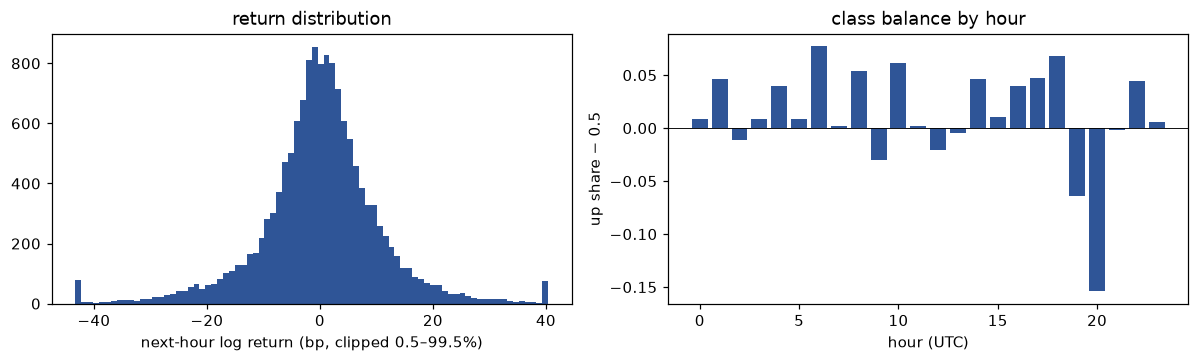

Up share 0.5122; by hour it ranges 0.346–0.577 (±1σ sampling noise per hour ≈ 0.021).

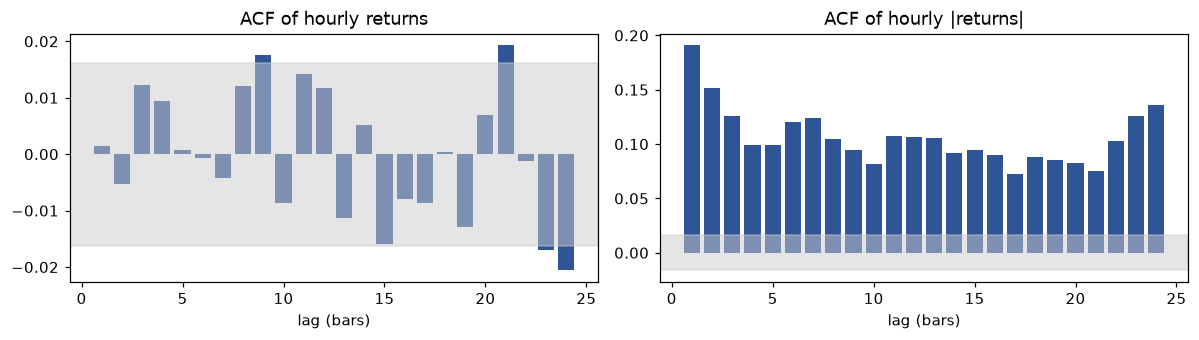

Return ACF outside the ±0.0162 band at lags [9, 21, 23, 24]; |return| ACF at lag 1 = 0.191 (volatility clusters, direction mostly does not).

,mean,std,min,max,missing,spearman_next_ret
hour_sin,0.0136,0.7090,-1.0000,1.0000,0.0000,0.0268
session_ny,0.3799,0.4854,0.0000,1.0000,0.0000,-0.0229
session_tokyo,0.3837,0.4863,0.0000,1.0000,0.0000,0.0223
hour,11.2671,6.8283,0.0000,23.0000,0.0000,-0.0223
ret_lag2,0.0000,0.0012,-0.0213,0.0147,0.0000,-0.0178
range_hl,0.0016,0.0013,0.0000,0.0298,0.0000,0.0165
vol_ratio_6_120,0.8768,0.4959,0.0479,4.5967,0.0000,0.0113
upper_wick,0.2659,0.1948,0.0000,0.9716,0.0002,0.0101
ret_std_120,0.0012,0.0005,0.0003,0.0032,0.0000,-0.0098
ret_std_24,0.0011,0.0006,0.0002,0.0051,0.0000,-0.0091


Largest |ρ| = 0.0268 (n = 14,270; ±2σ noise ≈ 0.0167). Single features carry very little linear signal.

[v001_lgbm_walkforward] Step4: 4 candidates: ['majority', 'momentum', 'logreg', 'lgbm']


[v001_lgbm_walkforward] Step5: walk-forward CV with TimeSeriesSplit(gap=24, max_train_size=None, n_splits=5, test_size=None)


...

[v001_lgbm_walkforward] Step8: holdout AUC 0.5583, acc 0.5496, strategy -0.147 bp/bar


[v001_lgbm_walkforward] Step9: artefacts under /Users/alhabib/Desktop/glitcj-repos/alpha-discovery/usdjpy-direction/outputs (28.3s)


,auc,auc_fold_std,log_loss,brier,accuracy,balanced_accuracy,strategy_bps,sharpe,turnover,n,fit_time_s
model,,,,,,,,,,,
lgbm,0.5187,0.0207,0.7002,0.2533,0.5168,0.5149,-0.2227,-1.4126,0.7022,11890.0000,1.3189
logreg,0.5101,0.0178,0.6977,0.2521,0.5138,0.5103,-0.2192,-1.3894,0.6410,11890.0000,0.0191
momentum,0.4925,0.0105,0.6996,0.2532,0.4929,0.4928,-0.6244,-3.9651,1.0129,11890.0000,0.0016
majority,0.4896,0.0000,0.6935,0.2502,0.5085,0.5000,-0.0311,-0.1976,0.0001,11890.0000,0.0031


,test_start,test_end,n_train,n_test,auc,log_loss,brier,accuracy,balanced_accuracy,pred_up_share,strategy_bps,sharpe,turnover
fold,,,,,,,,,,,,,
0,2024-06-12 01:00:00+00:00,2024-10-31 16:00:00+00:00,2356,2378,0.5022,0.7138,0.2598,0.5059,0.5084,0.7939,-0.4505,-2.2302,0.5109
1,2024-10-31 17:00:00+00:00,2025-03-25 22:00:00+00:00,4734,2378,0.5034,0.7070,0.2566,0.5004,0.5003,0.5055,-0.3009,-1.9277,0.8078
2,2025-03-25 23:00:00+00:00,2025-08-14 11:00:00+00:00,7112,2378,0.5389,0.6955,0.2510,0.5311,0.5323,0.5580,-0.0983,-0.5576,0.7851
3,2025-08-14 12:00:00+00:00,2026-01-06 18:00:00+00:00,9490,2378,0.5110,0.6987,0.2527,0.5029,0.4997,0.6009,-0.4767,-4.2393,0.6825
4,2026-01-06 19:00:00+00:00,2026-05-29 17:00:00+00:00,11868,2378,0.5537,0.6857,0.2464,0.5437,0.5366,0.6119,0.2133,1.7219,0.7237


,auc,log_loss,brier,accuracy,balanced_accuracy,strategy_bps,sharpe,turnover,fit_time_s
model,,,,,,,,,
lgbm,0.5512,0.6871,0.2470,0.5442,0.5378,0.2182,1.8164,0.7332,1.6274


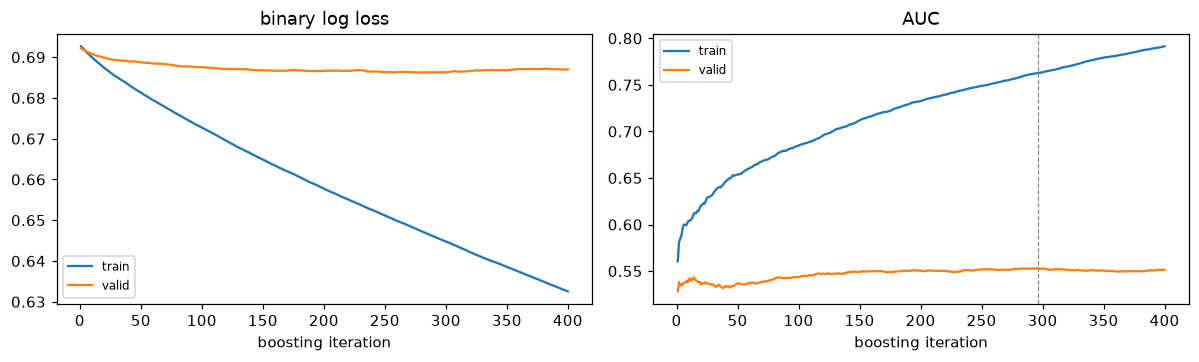

`lgbm`: best validation AUC 0.5530 at iteration 296 of 400. A widening train/valid gap means the extra trees fit noise.

,auc,auc_fold_std,log_loss,brier,accuracy,balanced_accuracy,strategy_bps,sharpe,turnover,n,fit_time_s
model,,,,,,,,,,,
lgbm (gap=0),0.5193,0.0202,0.7003,0.2534,0.5183,0.5165,-0.2199,-1.3945,0.7163,11890.0000,1.1806
lgbm,0.5187,0.0207,0.7002,0.2533,0.5168,0.5149,-0.2227,-1.4126,0.7022,11890.0000,1.3189
lgbm (rolling ~6-month window),0.5135,0.0140,0.7043,0.2553,0.5087,0.5075,-0.2419,-1.5352,0.7109,11890.0000,0.8805
lgbm (no calendar features),0.5057,0.0197,0.7035,0.2550,0.5078,0.5061,-0.3443,-2.1834,0.7503,11890.0000,1.0695


,n,share,up_share,auc,accuracy,strategy_bps
slice,,,,,,
tokyo,3553.0000,0.2988,0.5212,0.4853,0.4976,-0.5356
tokyo+london,1013.0000,0.0852,0.5252,0.4994,0.4936,-0.4692
london,1521.0000,0.1279,0.5122,0.5195,0.5141,-0.3998
london+ny,2026.0000,0.1704,0.5010,0.5186,0.5153,-0.3385
ny,2490.0000,0.2094,0.4847,0.5608,0.5502,0.2543
off-hours,1287.0000,0.1082,0.5136,0.5266,0.5291,0.0729


,n,share,up_share,auc,accuracy,strategy_bps
slice,,,,,,
00-03,2030.0000,0.1707,0.5034,0.4736,0.4783,-0.7737
04-07,2030.0000,0.1707,0.5310,0.4917,0.5099,-0.4383
08-11,2027.0000,0.1705,0.5244,0.5228,0.5150,-0.2699
12-15,2026.0000,0.1704,0.5010,0.5186,0.5153,-0.3385
16-19,2030.0000,0.1707,0.5182,0.5331,0.5335,0.1664
20-23,1747.0000,0.1469,0.4671,0.5666,0.5541,0.1707


,n,share,up_share,auc,accuracy,strategy_bps
slice,,,,,,
Mon,2408.0000,0.2025,0.5083,0.5109,0.5150,-0.1917
Tue,2440.0000,0.2052,0.4930,0.5297,0.5184,-0.2760
Wed,2432.0000,0.2045,0.5152,0.5381,0.5304,0.2256
Thu,2435.0000,0.2048,0.5125,0.5208,0.5133,-0.3015
Fri,2118.0000,0.1781,0.5189,0.4938,0.5076,-0.6037
Sun,57.0000,0.0048,0.3333,0.3906,0.4386,-1.7892


,n,share,up_share,auc,accuracy,strategy_bps
slice,,,,,,
low vol,3964.0000,0.3334,0.5189,0.5283,0.5283,-0.1920
mid vol,3963.0000,0.3333,0.5095,0.5198,0.5160,-0.4141
high vol,3963.0000,0.3333,0.4971,0.5085,0.5062,-0.0645


,n,share,up_share,auc,accuracy,strategy_bps
slice,,,,,,
<1pp,1159.0000,0.0975,0.5220,0.5068,0.5022,-0.4997
1-2pp,1201.0000,0.1010,0.5246,0.4865,0.5004,-0.8641
2-5pp,3163.0000,0.2660,0.5156,0.4956,0.5055,-0.2271
5pp+,6367.0000,0.5355,0.4995,0.5277,0.5282,-0.0671


Read the confidence table first: a usable model's hit rate should rise with |P(up) − 0.5|. Here the top bucket hits 0.528 on n = 6367.

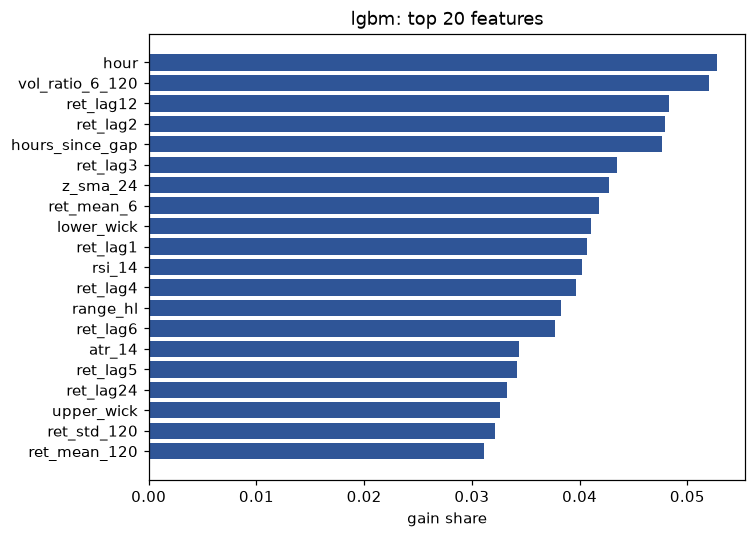

,auc,auc_fold_std,log_loss,brier,accuracy,balanced_accuracy,strategy_bps,sharpe,turnover,n,fit_time_s
model,,,,,,,,,,,
lgbm (CV),0.5187,0.0207,0.7002,0.2533,0.5168,0.5149,-0.2227,-1.4126,0.7022,11890.0000,1.3189
lgbm (holdout),0.5583,nan,0.6845,0.2458,0.5496,0.5414,-0.1470,-1.1952,0.6565,2518.0000,nan


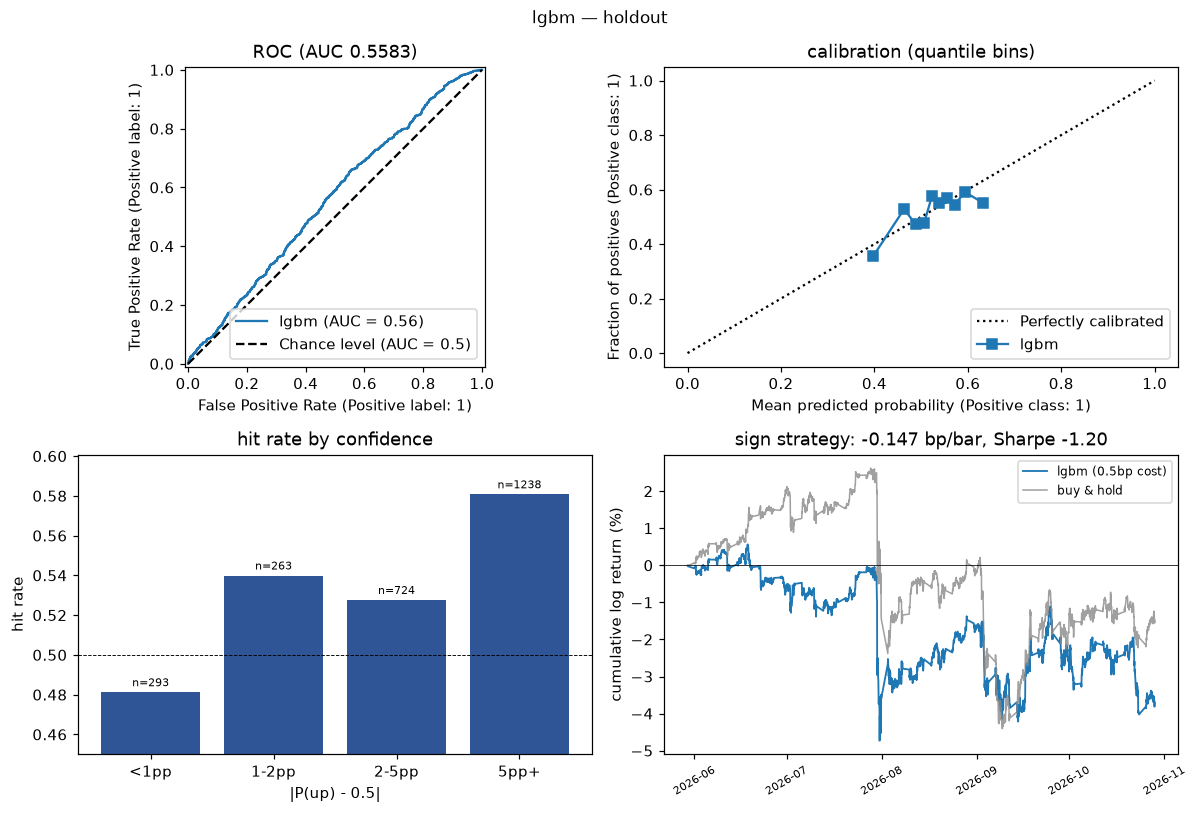

In [2]:
result = exp.run(display_preanalysis=True, display_postanalysis=True)

## Experiment ladder

`make experiments` evaluates a wider set of variants on the same development rows and walk-forward folds
(holdout excluded). The table is read from `outputs/experiments.json`.

In [3]:
path = Path("outputs/experiments.json")
if path.exists():
    ladder = json.loads(path.read_text())
    board = pd.DataFrame(ladder["results"]).set_index("model")
    display_dataframe(board, f"{ladder['cv']}-fold walk-forward, gap {ladder['gap']}, "
                             f"dev rows {ladder['n_dev']:,} ({ladder['dev_start'][:10]} → {ladder['dev_end'][:10]})")
else:
    display_info_box("outputs/experiments.json not found — run `make experiments`.", kind="warning")

,auc,auc_fold_std,log_loss,accuracy,strategy_bps,sharpe,fit_time_s
model,,,,,,,
lgbm: without candles,0.5226,0.0189,0.6996,0.5197,-0.1619,-1.0268,1.3570
"lgbm: library defaults (100 trees, 31 leaves)",0.5203,0.0170,0.7234,0.5192,-0.2159,-1.3694,0.7115
lgbm: tuned (v001),0.5187,0.0207,0.7002,0.5168,-0.2227,-1.4126,1.3407
"lgbm: stumps-ish (7 leaves, 800 trees, lr .01)",0.5181,0.0181,0.6976,0.5184,-0.3002,-1.9041,1.4048
lgbm: 100 trees only,0.5145,0.0230,0.6937,0.5192,-0.1921,-1.2186,0.3573
logreg: C=0.1,0.5101,0.0178,0.6977,0.5138,-0.2192,-1.3894,0.0167
reversal: fade last hour,0.5075,0.0105,0.6967,0.5075,-0.3884,-2.4658,0.0009
lgbm: without calendar,0.5057,0.0197,0.7035,0.5078,-0.3443,-2.1834,1.0368
lgbm: returns only,0.5017,0.0175,0.7025,0.5053,-0.5146,-3.2634,1.0025


## Findings (data 2024-01-15 → 2026-10-28, first run)

* **The signal is small.** LightGBM wins the walk-forward CV at AUC ≈ 0.52 (fold AUCs 0.50–0.55),
  ahead of logistic regression (≈ 0.51). Momentum and majority score ≤ 0.5. Hourly USDJPY returns have
  essentially no linear autocorrelation (|ACF| < 0.02); volatility clusters, direction does not.
* **Holdout AUC ≈ 0.56, accuracy ≈ 55%.** Much of that accuracy comes from the model leaning long
  (≈ 69% "up" calls) during a period in which USDJPY drifted up. One 5-month window is too short to
  call this an edge.
* **Costs eat it.** Before costs the sign strategy earns ≈ +0.2 bp/bar. The model flips position about every
  third bar (0.66 units of turnover per bar), so at 0.5 bp per unit of position change the net result is negative, both out-of-fold and
  on the holdout.
* **Where the edge is.** Removing calendar features drops CV AUC to ≈ 0.506, so most of what the model
  finds is time-of-day / session structure. AUC is highest in the NY session and in the most confident
  predictions (|P(up) − 0.5| ≥ 5pp).
* **Tuning doesn't matter (yet).** In the ladder every LightGBM variant (defaults, 7-leaf/800 trees, no
  candle features, ...) lands at AUC 0.515–0.523, within one fold-std (≈ 0.02) of each other. Using
  return lags only gives 0.502: past price moves alone carry essentially no direction information.
* **No leakage found.** Random-walk bars score AUC ≈ 0.5 through the full pipeline, features are invariant
  to truncating the future, and `gap=0` scores the same as `gap=24`.

## Next arms

* `v002`: trade only when |P(up) − 0.5| exceeds a threshold, to cut turnover. Choose the threshold on CV,
  then report it on the holdout.
* `v003`: predict a longer horizon (4h / 1d direction) where costs are a smaller share of the move.
* `v004`: add cross-asset context (DXY, US–JP rate proxies, Nikkei / S&P futures) at the same timestamps.
* For anything beyond research, switch to a documented data source (see `planning-1hour-price-direction-classification.md`).